In [ ]:
# !pip install insightface onnxruntime
from PIL import Image
import numpy as np
from insightface.app import FaceAnalysis
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import matplotlib.patches as patches

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 94.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 4.8 MB/s eta 0:00:00


/usr/local/lib/python3.11/dist-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.6' (you have '2.0.4'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [6]:
# Khởi tạo InsightFace
app = FaceAnalysis(name='buffalo_l', providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
app.prepare(ctx_id=0, det_size=(640, 640))  # Kích thước ảnh đầu vào

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


In [9]:
# Đường dẫn đến 2 ảnh
img_path1 = "/kaggle/input/face-reg2/truong.jpg"
img_path2 = "/kaggle/input/face-reg2/vinh.jpg"
output_file = "face_vectors.npy"

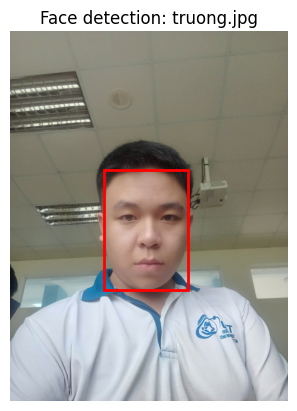

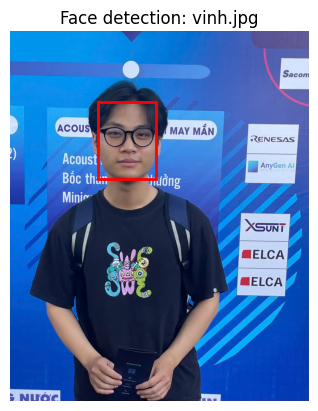

Saved 2 vectors to face_vectors.npy


In [12]:
def draw_bounding_box(img_array, faces, img_name):
    """Hiển thị ảnh với bounding box bằng matplotlib"""
    fig, ax = plt.subplots()
    ax.imshow(img_array)
    
    for face in faces:
        try:
            bbox = face['bbox']  # [x1, y1, x2, y2]
            rect = patches.Rectangle(
                (bbox[0], bbox[1]),  # Góc trên trái
                bbox[2] - bbox[0],  # Chiều rộng
                bbox[3] - bbox[1],  # Chiều cao
                linewidth=2, edgecolor='r', facecolor='none'
            )
            ax.add_patch(rect)
        except KeyError as e:
            print(f"Error: Face data missing bbox for {img_name}: {e}")
            continue
    
    plt.title(f"Face detection: {img_name}")
    plt.axis('off')
    plt.show()

def process_two_images(img_path1, img_path2, output_file):
    valid_vectors = []
    valid_paths = []
    image_paths = [img_path1, img_path2]

    for img_path in image_paths:
        img_name = img_path.split("/")[-1]  # Lấy tên file để hiển thị
        try:
            # Đọc ảnh với PIL
            img = Image.open(img_path).convert('RGB')
            img_array = np.array(img)  # Chuyển sang numpy array
        except Exception as e:
            print(f"Failed to load image {img_path}: {e}")
            continue

        # Face detection và feature extraction
        try:
            faces = app.get(img_array)  # Bỏ max_num để tránh lỗi
            if len(faces) == 0:
                print(f"No face detected in: {img_path}")
                continue
            if len(faces) > 1:
                print(f"Multiple faces detected in: {img_path}. Using the first face.")
        except Exception as e:
            print(f"Error during face detection for {img_path}: {e}")
            continue

        # Hiển thị ảnh với bounding box
        draw_bounding_box(img_array, faces, img_name)

        # Lấy embedding của khuôn mặt đầu tiên
        try:
            embedding = faces[0]['embedding']  # Vector 512 chiều
            if embedding is not None:
                valid_vectors.append(embedding)
                valid_paths.append(img_path)
        except KeyError as e:
            print(f"Error: No embedding found for {img_path}: {e}")
            continue

    # Kiểm tra số lượng vector hợp lệ
    if len(valid_vectors) == 0:
        print("Error: No valid vectors extracted.")
        return

    # Lưu vector vào file .npy
    np.save(output_file, np.array(valid_vectors, dtype=np.float32))
    np.save(output_file.replace('.npy', '_paths.npy'), np.array(valid_paths, dtype=object))
    print(f"Saved {len(valid_vectors)} vectors to {output_file}")

# Chạy pipeline
if __name__ == "__main__":
    process_two_images(img_path1, img_path2, output_file)

In [18]:
import numpy as np

vectors = np.load('face_vectors.npy')
paths = np.load('face_vectors_paths.npy', allow_pickle=True)
for path, vector in zip(paths, vectors):
    print(f"Vector for {path}: {vector.shape}")


Vector for /kaggle/input/face-reg2/truong.jpg: (512,)
Vector for /kaggle/input/face-reg2/vinh.jpg: (512,)
